In [2]:
# ---- Setup: Drive + code + wandb (run this first, every session) ----
REPO_URL = "https://github.com/ammara-asif/fyp.git"   # <-- EDIT ONCE
BRANCH = "main"

import os, subprocess, sys
from google.colab import drive, userdata

# Drive must be mounted from the notebook kernel (never from a !python subprocess).
drive.mount("/content/drive")

# Code: fresh clone each session (Colab disk is wiped on reset), pull if it already exists.
# For a private repo, add a Colab secret GITHUB_TOKEN (a fine-grained read-only token).
CODE = "/content/fyp"
url = REPO_URL
try:
    tok = userdata.get("GITHUB_TOKEN")
    url = REPO_URL.replace("https://", f"https://{tok}@")
except Exception:
    pass
if os.path.isdir(CODE):
    subprocess.run(["git", "-C", CODE, "pull", "-q"], check=True)
else:
    subprocess.run(["git", "clone", "-q", "-b", BRANCH, url, CODE], check=True)
print(subprocess.check_output(["git", "-C", CODE, "log", "-1", "--oneline"]).decode())

# Dependencies (torch/torchvision come preinstalled with Colab's CUDA build; don't reinstall them).
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", f"{CODE}/requirements.txt"], check=True)

# wandb: key comes from the Colab secret WANDB_API_KEY (key icon in the left sidebar). Never hardcode it.
import wandb
wandb.login(key=userdata.get("WANDB_API_KEY"))

sys.path.insert(0, f"{CODE}/src")
# Python caches imported modules for the whole kernel session, so after a git pull
# a plain `import` would silently keep running the OLD code. Drop the cached copies.
for _m in ["fyp_infra", "stage1_runner", "stage1_analysis", "stage1_drift_diagnostic"]:
    sys.modules.pop(_m, None)
import torch
from fyp_infra import setup_paths, run_sweep, run_id, load_result
import stage1_runner as sr
paths = setup_paths()   # -> /content/drive/MyDrive/fyp_nested_cl/{data,results,logs}
print(paths)
# Hard stop for training: a CPU run is ~12x slower and its timings are useless for budgeting.
REQUIRE_GPU = False   # analysis only: CPU runtime is fine
if REQUIRE_GPU:
    assert torch.cuda.is_available(), "No GPU! Runtime -> Change runtime type -> T4 GPU, then restart."
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (CPU runtime)")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
6e27f76 drift dignosis



/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: ammara-asif125 (kashaf-saleem09-institute-of-business-administration) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


{'root': '/content/drive/MyDrive/fyp_nested_cl', 'data': '/content/drive/MyDrive/fyp_nested_cl/data', 'results': '/content/drive/MyDrive/fyp_nested_cl/results', 'logs': '/content/drive/MyDrive/fyp_nested_cl/logs', 'checkpoints': '/content/drive/MyDrive/fyp_nested_cl/checkpoints'}
GPU: none (CPU runtime)


In [3]:
import stage1_analysis as sa
import stage1_drift_diagnostic as dd
TRAIN_RUNS = sa.list_runs(paths, stage="stage1_control")
for r in TRAIN_RUNS:
    c = r["config"]; print(r["run_id"], c["lr_schedule"], "lr", c["lr"], "seed", c["seed"])
DCFGS = dd.diagnostic_configs(TRAIN_RUNS)

32e5df8b8886 flat lr 0.3 seed 2
7b3073002436 flat lr 0.3 seed 0
bf6b7bf5e853 llrd lr 0.5 seed 2
bf7c7b91a468 llrd lr 0.5 seed 1
f686172d0a03 flat lr 0.3 seed 1
f7af3b7e79aa llrd lr 0.5 seed 0


In [4]:
out = run_sweep(DCFGS, dd.diagnose_run, paths)

[1/6] a228a311bfa6 running
  task 1/19: deepest-level drift 7.2 pts
  task 2/19: deepest-level drift 4.6 pts
  task 3/19: deepest-level drift 13.6 pts
  task 4/19: deepest-level drift 10.4 pts
  task 5/19: deepest-level drift 6.4 pts
  task 6/19: deepest-level drift 17.0 pts
  task 7/19: deepest-level drift 10.6 pts
  task 8/19: deepest-level drift 6.0 pts
  task 9/19: deepest-level drift 6.4 pts
  task 10/19: deepest-level drift 12.4 pts
  task 11/19: deepest-level drift 9.2 pts
  task 12/19: deepest-level drift 8.6 pts
  task 13/19: deepest-level drift 13.8 pts
  task 14/19: deepest-level drift 12.4 pts
  task 15/19: deepest-level drift 10.8 pts
  task 16/19: deepest-level drift 11.8 pts
  task 17/19: deepest-level drift 11.0 pts
  task 18/19: deepest-level drift 10.2 pts
  task 19/19: deepest-level drift 4.2 pts
[2/6] 9678e2a53e22 running


/content/fyp/src/stage1_drift_diagnostic.py:149: RuntimeWarning: Mean of empty slice
  mean = {c: np.nanmean(acc[c], axis=1) for c in CONDITIONS}


  task 1/19: deepest-level drift 3.4 pts
  task 2/19: deepest-level drift 6.0 pts
  task 3/19: deepest-level drift 8.2 pts
  task 4/19: deepest-level drift 9.8 pts
  task 5/19: deepest-level drift 9.8 pts
  task 6/19: deepest-level drift 17.2 pts
  task 7/19: deepest-level drift 9.0 pts
  task 8/19: deepest-level drift 9.6 pts
  task 9/19: deepest-level drift 10.8 pts
  task 10/19: deepest-level drift 11.2 pts
  task 11/19: deepest-level drift 14.2 pts
  task 12/19: deepest-level drift 11.4 pts
  task 13/19: deepest-level drift 14.0 pts
  task 14/19: deepest-level drift 14.4 pts
  task 15/19: deepest-level drift 10.6 pts
  task 16/19: deepest-level drift 9.0 pts
  task 17/19: deepest-level drift 9.8 pts
  task 18/19: deepest-level drift 10.2 pts
  task 19/19: deepest-level drift 8.8 pts
[3/6] ba78a5e99362 running


/content/fyp/src/stage1_drift_diagnostic.py:149: RuntimeWarning: Mean of empty slice
  mean = {c: np.nanmean(acc[c], axis=1) for c in CONDITIONS}


  task 1/19: deepest-level drift 5.0 pts
  task 2/19: deepest-level drift 4.0 pts
  task 3/19: deepest-level drift 11.2 pts
  task 4/19: deepest-level drift 11.4 pts
  task 5/19: deepest-level drift 5.6 pts
  task 6/19: deepest-level drift 16.0 pts
  task 7/19: deepest-level drift 6.8 pts
  task 8/19: deepest-level drift 4.4 pts
  task 9/19: deepest-level drift 6.4 pts
  task 10/19: deepest-level drift 11.6 pts
  task 11/19: deepest-level drift 6.6 pts
  task 12/19: deepest-level drift 6.2 pts
  task 13/19: deepest-level drift 9.2 pts
  task 14/19: deepest-level drift 15.4 pts
  task 15/19: deepest-level drift 8.2 pts
  task 16/19: deepest-level drift 12.0 pts
  task 17/19: deepest-level drift 7.6 pts
  task 18/19: deepest-level drift 10.0 pts
  task 19/19: deepest-level drift 8.4 pts
[4/6] 1b5c130aeb19 running


...

/content/fyp/src/stage1_drift_diagnostic.py:149: RuntimeWarning: Mean of empty slice
  mean = {c: np.nanmean(acc[c], axis=1) for c in CONDITIONS}


  task 1/19: deepest-level drift 5.8 pts
  task 2/19: deepest-level drift 3.6 pts
  task 3/19: deepest-level drift 6.6 pts
  task 4/19: deepest-level drift 7.2 pts
  task 5/19: deepest-level drift 13.8 pts
  task 6/19: deepest-level drift 5.6 pts
  task 7/19: deepest-level drift 7.4 pts
  task 8/19: deepest-level drift 14.4 pts
  task 9/19: deepest-level drift 13.4 pts
  task 10/19: deepest-level drift 16.4 pts
  task 11/19: deepest-level drift 10.4 pts
  task 12/19: deepest-level drift 6.8 pts
  task 13/19: deepest-level drift 11.2 pts
  task 14/19: deepest-level drift 11.8 pts
  task 15/19: deepest-level drift 12.0 pts
  task 16/19: deepest-level drift 11.4 pts
  task 17/19: deepest-level drift 11.4 pts
  task 18/19: deepest-level drift 9.8 pts
  task 19/19: deepest-level drift 9.2 pts
[6/6] e1f4886708d2 running


/content/fyp/src/stage1_drift_diagnostic.py:149: RuntimeWarning: Mean of empty slice
  mean = {c: np.nanmean(acc[c], axis=1) for c in CONDITIONS}


  task 1/19: deepest-level drift 2.0 pts
  task 2/19: deepest-level drift 3.4 pts
  task 3/19: deepest-level drift 7.8 pts
  task 4/19: deepest-level drift 8.2 pts
  task 5/19: deepest-level drift 12.8 pts
  task 6/19: deepest-level drift 12.2 pts
  task 7/19: deepest-level drift 9.0 pts
  task 8/19: deepest-level drift 9.6 pts
  task 9/19: deepest-level drift 7.4 pts
  task 10/19: deepest-level drift 10.6 pts
  task 11/19: deepest-level drift 16.2 pts
  task 12/19: deepest-level drift 9.4 pts
  task 13/19: deepest-level drift 17.6 pts
  task 14/19: deepest-level drift 13.2 pts
  task 15/19: deepest-level drift 8.0 pts
  task 16/19: deepest-level drift 12.2 pts
  task 17/19: deepest-level drift 11.0 pts
  task 18/19: deepest-level drift 8.4 pts
  task 19/19: deepest-level drift 6.8 pts


/content/fyp/src/stage1_drift_diagnostic.py:149: RuntimeWarning: Mean of empty slice
  mean = {c: np.nanmean(acc[c], axis=1) for c in CONDITIONS}


In [5]:
import numpy as np, pandas as pd
PARTS = ["total_drift", "own_drift", "inherited_drift", "interaction", "bn_recovery", "bn_procedure_effect"]
rows = []
for a in DCFGS:
    r = load_result(a, paths)
    if r is None: continue
    m = r["metrics"]; c = m["train_config"]
    for l, name in enumerate(m["level_modules"]):
        rows.append({"arm": c["lr_schedule"], "lr": c["lr"], "seed": c["seed"], "level": name,
                     **{p: m[p][l] for p in PARTS}})
ddf = pd.DataFrame(rows)
summary = ddf.drop(columns="seed").groupby(["arm", "lr", "level"]).agg(["mean", "std"]).round(2)
display(summary)

total_drift       own_drift       inherited_drift        \
                       mean   std      mean   std            mean   std   
arm  lr  level                                                            
flat 0.3 layer1        2.01  0.39      2.01  0.39            0.00  0.00   
         layer3        6.85  0.55      4.66  0.37            3.94  0.94   
         layer4       10.04  0.31      1.01  0.13            9.24  0.80   
llrd 0.5 layer1        1.28  0.93      1.28  0.93            0.00  0.00   
         layer3        6.98  1.23      5.19  1.26            5.16  0.93   
         layer4       10.02  1.42      0.58  0.14           10.22  1.70   

                interaction       bn_recovery       bn_procedure_effect        
                       mean   std        mean   std                mean   std  
arm  lr  level                                                                 
flat 0.3 layer1        0.00  0.00        0.21  0.18               -0.12  0.38  
         layer3       -1.74  0.95       -0.17  0.44               -0.32  0.23  
         layer4       -0.21  0.61       -0.32  0.36               -0.86  0.50  
llrd 0.5 layer1        0.00  0.00       -0.16  0.12                0.01  0.87  
         layer3       -3.38  0.73       -0.29  0.37               -0.61  0.35  
         layer4       -0.77  0.44       -0.34  0.67               -1.21  0.79

In [6]:
diffs = []
for a in DCFGS:
    r = load_result(a, paths)
    ra = load_result({"analysis": sa.ANALYSIS_VERSION, "train_run_id": a["train_run_id"]}, paths)
    if r is None or ra is None: continue
    diffs += [abs(x - y) for x, y in zip(r["metrics"]["total_drift"], ra["metrics"]["probe_forgetting"])]
print(f"max |total_drift - probe_forgetting| = {max(diffs):.3f} points over {len(diffs)} values" if diffs
      else "no stage1_analysis results found to compare against")

max |total_drift - probe_forgetting| = 0.000 points over 18 values


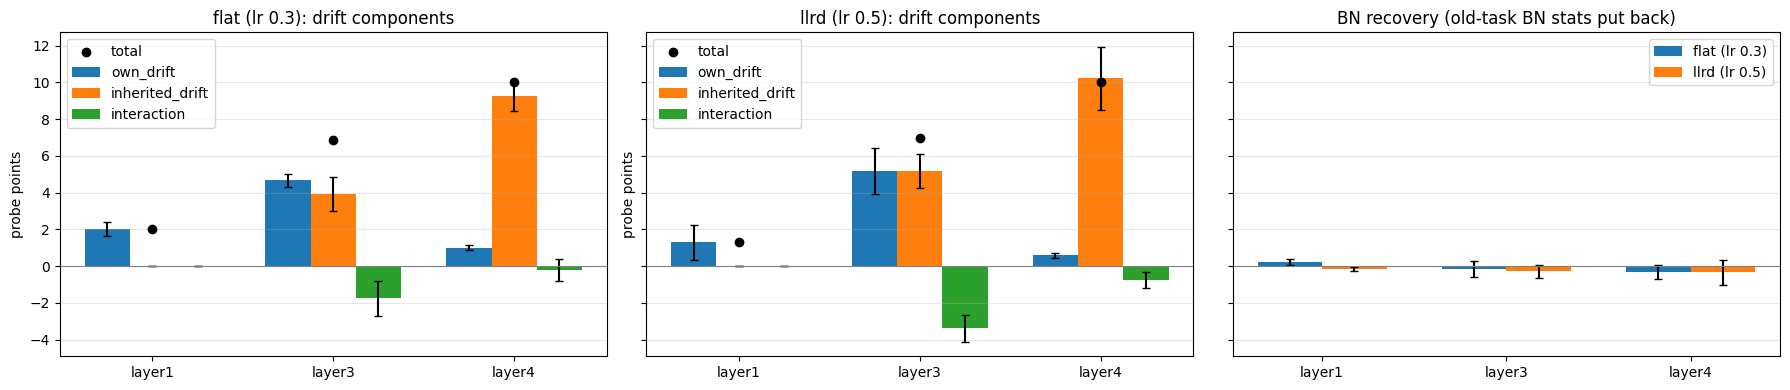

In [7]:
import matplotlib.pyplot as plt
levels = list(dict.fromkeys(ddf["level"]))
arms = list(dict.fromkeys(zip(ddf["arm"], ddf["lr"])))
comps = ["own_drift", "inherited_drift", "interaction"]
fig, axes = plt.subplots(1, len(arms) + 1, figsize=(6 * (len(arms) + 1), 4), sharey=True)
for ax, (arm, lr) in zip(axes, arms):
    g = ddf[(ddf["arm"] == arm) & (ddf["lr"] == lr)]
    w = 0.25
    for k, comp in enumerate(comps):
        stats = g.groupby("level")[comp].agg(["mean", "std"]).reindex(levels)
        ax.bar(np.arange(len(levels)) + (k - 1) * w, stats["mean"], w, yerr=stats["std"], capsize=3, label=comp)
    tot = g.groupby("level")["total_drift"].mean().reindex(levels)
    ax.scatter(np.arange(len(levels)), tot, color="black", zorder=3, label="total")
    ax.set(title=f"{arm} (lr {lr}): drift components", xticks=range(len(levels)), xticklabels=levels, ylabel="probe points")
    ax.axhline(0, color="grey", lw=.8); ax.legend(); ax.grid(alpha=.3, axis="y")
ax = axes[-1]
for k, (arm, lr) in enumerate(arms):
    g = ddf[(ddf["arm"] == arm) & (ddf["lr"] == lr)]
    stats = g.groupby("level")["bn_recovery"].agg(["mean", "std"]).reindex(levels)
    ax.bar(np.arange(len(levels)) + (k - 0.5) * 0.35, stats["mean"], 0.35, yerr=stats["std"], capsize=3, label=f"{arm} (lr {lr})")
ax.set(title="BN recovery (old-task BN stats put back)", xticks=range(len(levels)), xticklabels=levels)
ax.axhline(0, color="grey", lw=.8); ax.legend(); ax.grid(alpha=.3, axis="y")
plt.tight_layout(); plt.show()